In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, HuberRegressor, RANSACRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Upload Housing.csv when prompted
from google.colab import files
uploaded = files.upload()

# Load Dataset
df = pd.read_csv('Housing.csv')
print("Dataset Shape:", df.shape)
df.head()

Saving Housing.csv to Housing.csv
Dataset Shape: (545, 13)


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


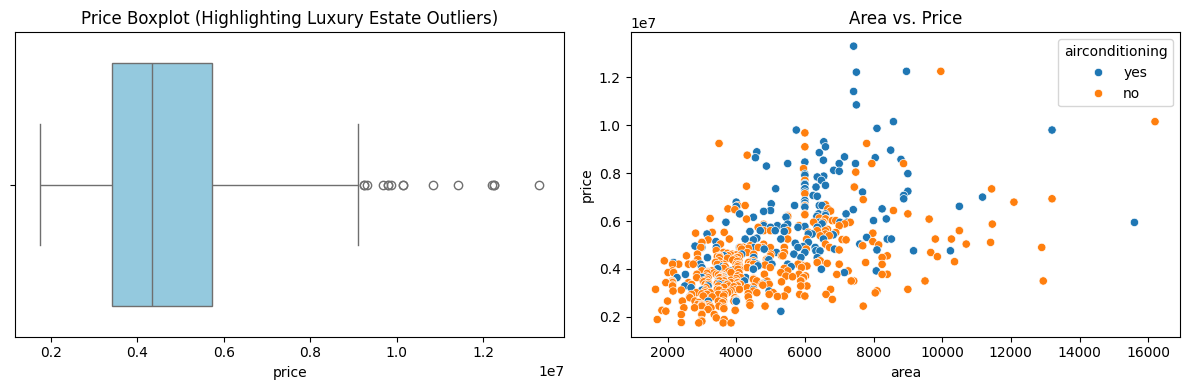

In [ ]:
# Check target variable distribution for outliers
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
sns.boxplot(x=df['price'], color='skyblue')
plt.title("Price Boxplot (Highlighting Luxury Estate Outliers)")

plt.subplot(1, 2, 2)
sns.scatterplot(x=df['area'], y=df['price'], hue=df['airconditioning'])
plt.title("Area vs. Price")

plt.tight_layout()
plt.show()

In [ ]:
# Convert categorical binary variables (yes/no) and furnishing status to numeric
df_encoded = pd.get_dummies(df, drop_first=True)

# Separate features (X) and target variable (y)
X = df_encoded.drop('price', axis=1)
y = df_encoded['price']

# Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Feature Scaling (Crucial for Huber Regressor and Gradient-based solvers)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
# 1. Standard OLS Linear Regression
ols_model = LinearRegression()
ols_model.fit(X_train_scaled, y_train)

# 2. Huber Regression (Unit 2 Robust Loss)
huber_model = HuberRegressor(epsilon=1.35, max_iter=1000)
huber_model.fit(X_train_scaled, y_train)

# 3. RANSAC Regression (Unit 2 Outlier Mitigation)
ransac_model = RANSACRegressor(estimator=LinearRegression(), random_state=42)
ransac_model.fit(X_train_scaled, y_train)

RANSACRegressor(estimator=LinearRegression(), random_state=42)

In [ ]:
# Step 5: Evaluate and compare model metrics
models = {
    'OLS Linear Regression': ols_model,
    'Huber Regression': huber_model,
    'RANSAC Regression': ransac_model
}

results = []

for name, model in models.items():
    preds = model.predict(X_test_scaled)
    mae = mean_absolute_error(y_test, preds)
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    r2 = r2_score(y_test, preds)
    results.append({'Model': name, 'MAE': mae, 'RMSE': rmse, 'R2 Score': r2})

results_df = pd.DataFrame(results)
print("=== PERFORMANCE COMPARISON ===")
display(results_df)

=== PERFORMANCE COMPARISON ===


,Model,MAE,RMSE,R2 Score
0,OLS Linear Regression,9.700434e+05,1.324507e+06,0.652924
1,Huber Regression,9.860372e+05,1.415859e+06,0.603397
2,RANSAC Regression,1.097727e+06,1.527717e+06,0.538256


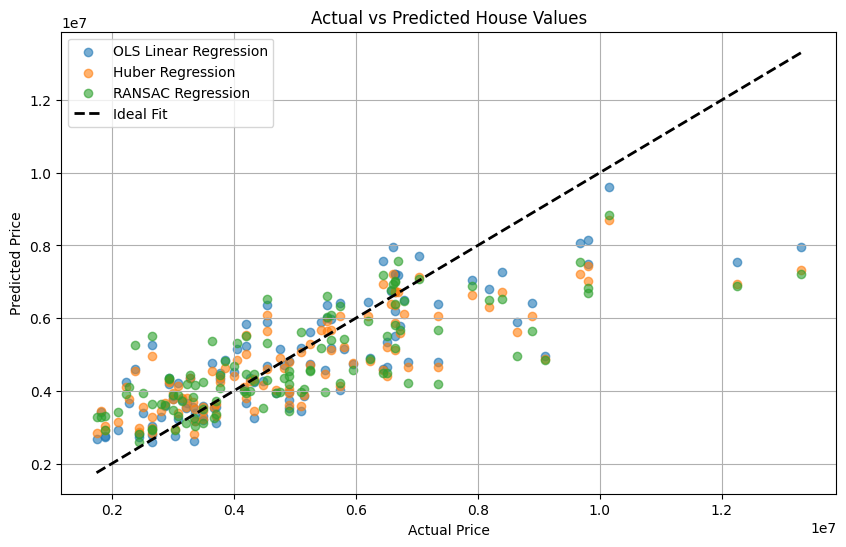

In [ ]:
# Identify inliers vs. outliers detected by RANSAC
inlier_mask = ransac_model.inlier_mask_
outlier_mask = np.logical_not(inlier_mask)

# Plot actual vs predicted for test set
plt.figure(figsize=(10, 6))
for name, model in models.items():
    preds = model.predict(X_test_scaled)
    plt.scatter(y_test, preds, label=name, alpha=0.6)

plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=2, label='Ideal Fit')
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted House Values")
plt.legend()
plt.grid(True)
plt.show()